In [1]:

# ============================================================
# BIML 2.0 — CELL 1: ENVIRONMENT AND PROJECT CONFIGURATION
# ============================================================

from pathlib import Path
import sys
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

PROJECT = Path.cwd()
DATA_DIR = PROJECT / "data"
OUTPUT_DIR = PROJECT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

ENV_FILE = DATA_DIR / "Environmental_2013_2024_with_ERA5_T2M.csv"
INC_FILE = DATA_DIR / "Incidence_history_32countries_2012_2024.csv"

print("=" * 65)
print("BIML 2.0 — REPRODUCIBLE RESEARCH ENVIRONMENT")
print("=" * 65)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Platform:", platform.platform())
print("Project directory:", PROJECT)
print("Environment file exists:", ENV_FILE.exists())
print("Incidence file exists:", INC_FILE.exists())


BIML 2.0 — REPRODUCIBLE RESEARCH ENVIRONMENT
Python: 3.12.12
Pandas: 2.3.3
NumPy: 2.4.3
Scikit-learn: 1.8.0
Platform: Linux-7.0.0-38-generic-x86_64-with-glibc2.43
Project directory: /home/gato/Desktop/BIML_
Environment file exists: False
Incidence file exists: False


In [2]:

# ============================================================
# CELL 2: LOAD ORIGINAL DATA WITHOUT ALTERING SOURCE FILES
# ============================================================

env = pd.read_csv(ENV_FILE)
inc = pd.read_csv(INC_FILE)

print("=" * 65)
print("ORIGINAL DATASET STRUCTURE")
print("=" * 65)

for name, df in [("ENVIRONMENT", env), ("INCIDENCE", inc)]:
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Countries:", df["Country"].nunique())
    print("Years:", df["Year"].min(), "-", df["Year"].max())
    print("Duplicate rows:", df.duplicated().sum())
    print("\nColumns:")
    print(df.dtypes.to_string())
    print("\nMissing values:")
    print(df.isna().sum().to_string())

required_env = [
    "Country", "Year", "Month", "Date",
    "ERA5_T2M_C", "Rainfall_mm", "RH_pct",
    "Landsat_LST_C", "MODIS_Night_LST_C",
    "NDVI", "NDWI"
]

required_inc = [
    "Country", "Year",
    "Malaria_incidence_per_1000", "Incidence_lag1"
]

assert set(required_env).issubset(env.columns)
assert set(required_inc).issubset(inc.columns)

print("\nRequired columns verified.")


ORIGINAL DATASET STRUCTURE

ENVIRONMENT
Shape: (4608, 21)
Countries: 32
Years: 2013 - 2024
Duplicate rows: 0

Columns:
Country                        object
Year                            int64
Month                         float64
Date                           object
Landsat_LST_C                 float64
MODIS_Night_LST_C             float64
Rainfall_mm                   float64
RH_pct                        float64
NDVI                          float64
NDWI                          float64
Landsat_scene_count             int64
Landsat_valid_coverage_pct    float64
MODIS_composite_count           int64
Landsat_available               int64
MODIS_available                 int64
Rainfall_available              int64
RH_available                    int64
NDVI_available                  int64
NDWI_available                  int64
ERA5_T2M_C                    float64
ERA5_T2M_available              int64

Missing values:
Country                        0
Year                           0


In [3]:

# ============================================================
# CELL 3: PANEL INTEGRITY AND LAG VALIDATION
# ============================================================

env["Country"] = env["Country"].str.strip()
inc["Country"] = inc["Country"].str.strip()

env["Year"] = pd.to_numeric(env["Year"], errors="raise").astype(int)
inc["Year"] = pd.to_numeric(inc["Year"], errors="raise").astype(int)

env["Month"] = pd.to_numeric(
    env["Month"], errors="raise"
).astype(int)

env["Date"] = pd.to_datetime(
    env["Date"].astype(str), format="%Y-%m", errors="raise"
)

assert env[["Country", "Year", "Month"]].duplicated().sum() == 0
assert inc[["Country", "Year"]].duplicated().sum() == 0

assert (env["Year"] == env["Date"].dt.year).all()
assert (env["Month"] == env["Date"].dt.month).all()

expected_env = pd.MultiIndex.from_product(
    [sorted(env["Country"].unique()),
     range(2013, 2025),
     range(1, 13)],
    names=["Country", "Year", "Month"]
)

actual_env = pd.MultiIndex.from_frame(
    env[["Country", "Year", "Month"]]
)

expected_inc = pd.MultiIndex.from_product(
    [sorted(inc["Country"].unique()), range(2012, 2025)],
    names=["Country", "Year"]
)

actual_inc = pd.MultiIndex.from_frame(
    inc[["Country", "Year"]]
)

print("Missing environmental keys:",
      len(expected_env.difference(actual_env)))
print("Unexpected environmental keys:",
      len(actual_env.difference(expected_env)))
print("Missing incidence keys:",
      len(expected_inc.difference(actual_inc)))
print("Unexpected incidence keys:",
      len(actual_inc.difference(expected_inc)))

assert set(env["Country"]) == set(inc["Country"])
assert expected_env.equals(actual_env.sort_values())
assert expected_inc.equals(actual_inc.sort_values())

inc = inc.sort_values(["Country", "Year"]).copy()

inc["recomputed_lag1"] = (
    inc.groupby("Country")["Malaria_incidence_per_1000"].shift(1)
)

valid = inc["Year"] >= 2013

lag_matches = np.isclose(
    inc.loc[valid, "Incidence_lag1"],
    inc.loc[valid, "recomputed_lag1"],
    rtol=0, atol=1e-8
)

assert lag_matches.all(), "INCIDENCE LAG MISMATCH DETECTED"

assert inc.loc[valid, "Malaria_incidence_per_1000"].notna().all()
assert inc.loc[valid, "Incidence_lag1"].notna().all()

print("\nAll panel and incidence-lag integrity checks passed.")


Missing environmental keys: 0
Unexpected environmental keys: 0
Missing incidence keys: 0
Unexpected incidence keys: 0

All panel and incidence-lag integrity checks passed.


In [4]:

# ============================================================
# CELL 4: RECONSTRUCT COUNTRY-YEAR PANEL
# ============================================================

env_features = [
    "ERA5_T2M_C",
    "Rainfall_mm",
    "RH_pct",
    "Landsat_LST_C",
    "MODIS_Night_LST_C",
    "NDVI",
    "NDWI"
]

env = env.sort_values(
    ["Country", "Year", "Month"]
).reset_index(drop=True)

annual = (
    env.groupby(["Country", "Year"])[env_features]
    .agg(["mean", "std", "min", "max", "count"])
)

annual.columns = [
    f"{variable}_{statistic}"
    for variable, statistic in annual.columns
]

annual = annual.reset_index()

# Rainfall total is different from mean monthly rainfall.
rainfall_total = (
    env.groupby(["Country", "Year"])["Rainfall_mm"]
    .sum(min_count=1)
    .rename("Rainfall_annual_total_mm")
    .reset_index()
)

annual = annual.merge(
    rainfall_total,
    on=["Country", "Year"],
    validate="one_to_one"
)

target = inc.loc[
    inc["Year"] >= 2013,
    ["Country", "Year",
     "Malaria_incidence_per_1000", "Incidence_lag1"]
].copy()

panel = target.merge(
    annual,
    on=["Country", "Year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (panel["_merge"] == "both").all()
panel = panel.drop(columns="_merge")

assert panel.shape[0] == 384
assert panel["Malaria_incidence_per_1000"].notna().all()

panel = panel.sort_values(
    ["Country", "Year"]
).reset_index(drop=True)

panel["Incidence_change"] = (
    panel["Malaria_incidence_per_1000"]
    - panel["Incidence_lag1"]
)

panel["Incidence_relative_change"] = (
    panel["Incidence_change"]
    / panel["Incidence_lag1"].replace(0, np.nan)
)

panel["Persistence_abs_error"] = (
    panel["Incidence_change"].abs()
)

print("Final panel shape:", panel.shape)
print("Countries:", panel["Country"].nunique())
print("Years:", panel["Year"].nunique())

print("\nIncidence distribution:")
print(
    panel["Malaria_incidence_per_1000"]
    .describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
)

print("\nAnnual incidence-change distribution:")
print(
    panel["Incidence_change"]
    .describe(percentiles=[.05, .25, .5, .75, .95])
)

panel.to_csv(
    DATA_DIR / "BIML_annual_audit_panel.csv",
    index=False
)

print("\nAnnual audit panel saved.")


Final panel shape: (384, 43)
Countries: 32
Years: 12

Incidence distribution:
count    384.000000
mean     231.007891
std      121.346421
min        0.140000
1%         0.446200
5%         7.227000
25%      131.367500
50%      259.535000
75%      321.445000
95%      394.690500
99%      441.873800
max      711.440000
Name: Malaria_incidence_per_1000, dtype: float64

Annual incidence-change distribution:
count    384.000000
mean      -3.191589
std       23.971431
min     -233.870000
5%       -23.653000
25%       -9.842500
50%       -2.700000
75%        2.835000
95%       21.298000
max      295.520000
Name: Incidence_change, dtype: float64

Annual audit panel saved.


TARGET DYNAMICS
Overall persistence MAE: 11.2398
Overall persistence RMSE: 24.152
Target-lag Pearson correlation: 0.9814
Median country incidence SD: 13.3028
Median country persistence MAE: 9.5333

COUNTRY DIAGNOSTICS
                                  mean_incidence  sd_incidence  mean_abs_change  persistence_mae  max_abs_change  coefficient_variation
Country                                                                                                                                
Burkina Faso                             433.744        97.572           64.250           64.250          295.52                  0.225
Ethiopia                                 176.828        16.708           16.257           16.257           46.93                  0.094
United Republic of Tanzania              118.080        20.746           15.950           15.950           36.25                  0.176
Angola                                   135.818        18.156           14.851           14.851      

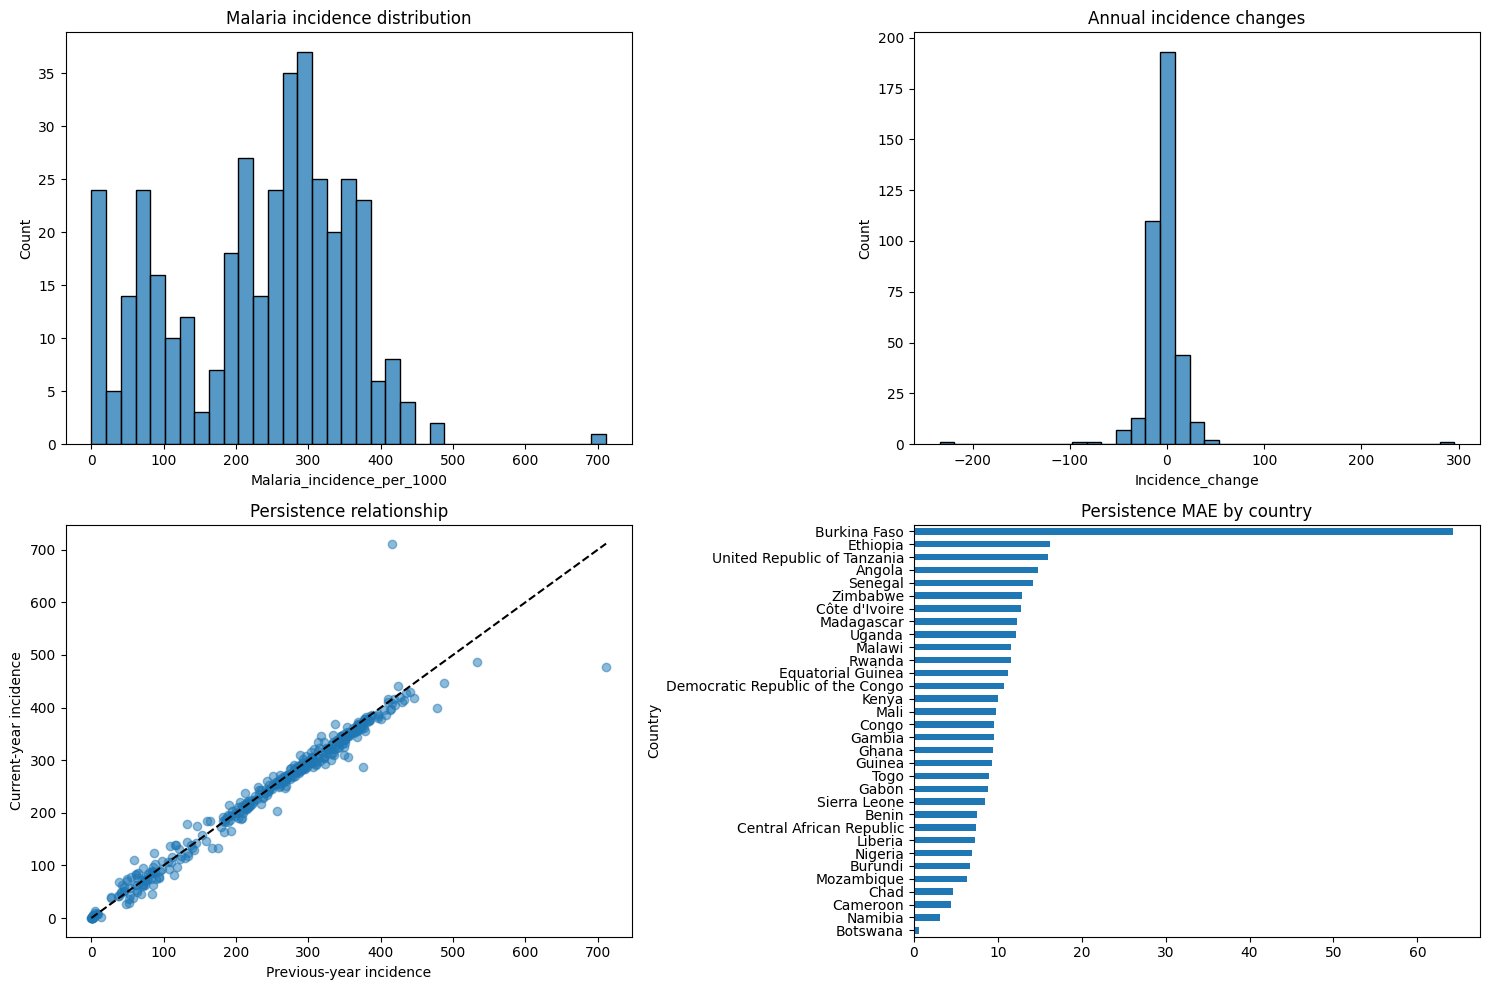

In [5]:

# ============================================================
# CELL 5: TARGET DYNAMICS AND PERSISTENCE DIAGNOSTICS
# ============================================================

y = panel["Malaria_incidence_per_1000"]
lag = panel["Incidence_lag1"]

mae = np.mean(np.abs(y - lag))
rmse = np.sqrt(np.mean((y - lag) ** 2))

country_stats = (
    panel.groupby("Country")
    .agg(
        mean_incidence=("Malaria_incidence_per_1000", "mean"),
        sd_incidence=("Malaria_incidence_per_1000", "std"),
        mean_abs_change=("Incidence_change", lambda x: x.abs().mean()),
        persistence_mae=("Persistence_abs_error", "mean"),
        max_abs_change=("Incidence_change", lambda x: x.abs().max())
    )
    .sort_values("persistence_mae", ascending=False)
)

country_stats["coefficient_variation"] = (
    country_stats["sd_incidence"]
    / country_stats["mean_incidence"].replace(0, np.nan)
)

print("=" * 65)
print("TARGET DYNAMICS")
print("=" * 65)

print("Overall persistence MAE:", round(mae, 4))
print("Overall persistence RMSE:", round(rmse, 4))
print("Target-lag Pearson correlation:", round(y.corr(lag), 4))
print("Median country incidence SD:",
      round(country_stats["sd_incidence"].median(), 4))
print("Median country persistence MAE:",
      round(country_stats["persistence_mae"].median(), 4))

print("\nCOUNTRY DIAGNOSTICS")
print(country_stats.round(3).to_string())

country_stats.to_csv(
    TABLE_DIR / "country_target_diagnostics.csv"
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(y, bins=35, ax=axes[0, 0])
axes[0, 0].set_title("Malaria incidence distribution")

sns.histplot(panel["Incidence_change"], bins=35, ax=axes[0, 1])
axes[0, 1].set_title("Annual incidence changes")

axes[1, 0].scatter(lag, y, alpha=0.5)
lims = [min(lag.min(), y.min()), max(lag.max(), y.max())]
axes[1, 0].plot(lims, lims, linestyle="--", color="black")
axes[1, 0].set_xlabel("Previous-year incidence")
axes[1, 0].set_ylabel("Current-year incidence")
axes[1, 0].set_title("Persistence relationship")

country_stats["persistence_mae"].sort_values().plot(
    kind="barh", ax=axes[1, 1]
)
axes[1, 1].set_title("Persistence MAE by country")

plt.tight_layout()
plt.savefig(FIG_DIR / "target_diagnostics.png", dpi=250)
plt.show()


EXPLORATORY ENVIRONMENTAL RELATIONSHIPS
DEVELOPMENT PERIOD ONLY: 2013–2020

TARGET: Malaria_incidence_per_1000
                 feature                     target   n  pearson  spearman  abs_spearman
         ERA5_T2M_C_mean Malaria_incidence_per_1000 256   0.5140    0.5054        0.5054
          ERA5_T2M_C_max Malaria_incidence_per_1000 256   0.4354    0.4393        0.4393
          ERA5_T2M_C_min Malaria_incidence_per_1000 256   0.5325    0.4193        0.4193
  MODIS_Night_LST_C_mean Malaria_incidence_per_1000 256   0.5441    0.4169        0.4169
                NDVI_max Malaria_incidence_per_1000 256   0.3353    0.4166        0.4166
              RH_pct_max Malaria_incidence_per_1000 256   0.3092    0.3675        0.3675
                NDWI_min Malaria_incidence_per_1000 256  -0.2977   -0.3601        0.3601
        Rainfall_mm_mean Malaria_incidence_per_1000 256   0.3713    0.3518        0.3518
Rainfall_annual_total_mm Malaria_incidence_per_1000 256   0.3713    0.3518        0.3518

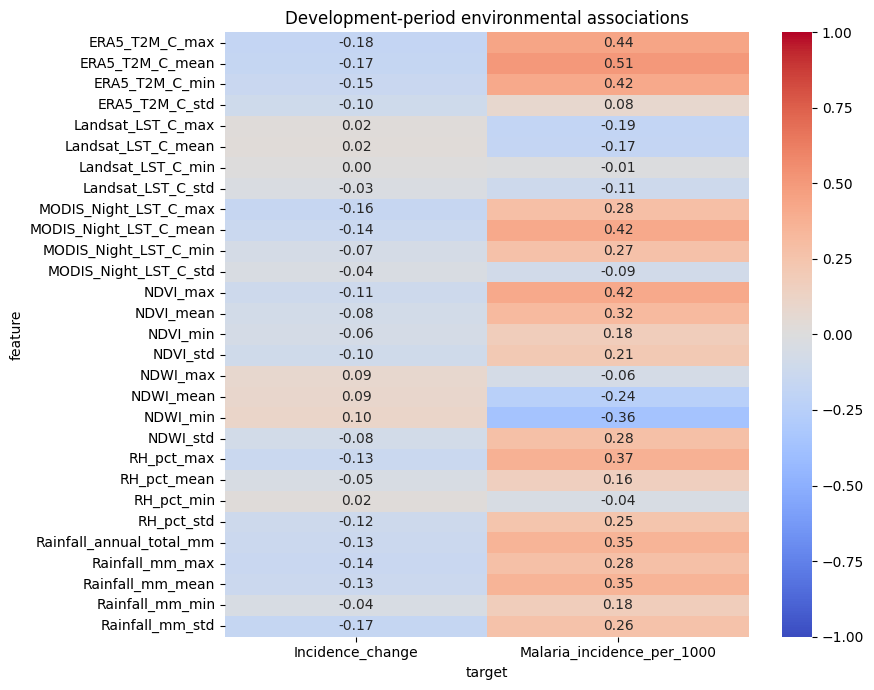

In [6]:

# ============================================================
# CELL 6: TRAINING-PERIOD ENVIRONMENTAL ASSOCIATIONS
# ============================================================

development = panel.loc[panel["Year"] <= 2020].copy()

feature_cols = [
    c for c in development.columns
    if any(c.startswith(f + "_") for f in env_features)
    or c == "Rainfall_annual_total_mm"
]

# Exclude observation counts from this initial
# environmental-value correlation analysis.
feature_cols = [
    c for c in feature_cols
    if not c.endswith("_count")
]

targets = [
    "Malaria_incidence_per_1000",
    "Incidence_change"
]

results = []

for feature in feature_cols:
    for target_name in targets:
        pair = development[[feature, target_name]].dropna()

        if len(pair) < 30:
            continue

        results.append({
            "feature": feature,
            "target": target_name,
            "n": len(pair),
            "pearson": pair[feature].corr(
                pair[target_name], method="pearson"
            ),
            "spearman": pair[feature].corr(
                pair[target_name], method="spearman"
            )
        })

correlation_results = pd.DataFrame(results)

correlation_results["abs_spearman"] = (
    correlation_results["spearman"].abs()
)

correlation_results = correlation_results.sort_values(
    ["target", "abs_spearman"],
    ascending=[True, False]
)

print("=" * 65)
print("EXPLORATORY ENVIRONMENTAL RELATIONSHIPS")
print("DEVELOPMENT PERIOD ONLY: 2013–2020")
print("=" * 65)

for target_name in targets:
    print("\nTARGET:", target_name)
    subset = correlation_results[
        correlation_results["target"] == target_name
    ]
    print(subset.head(20).round(4).to_string(index=False))

correlation_results.to_csv(
    TABLE_DIR / "development_correlations.csv",
    index=False
)

# Visualize Spearman associations.
pivot = correlation_results.pivot(
    index="feature",
    columns="target",
    values="spearman"
)

plt.figure(figsize=(9, max(7, len(pivot) * 0.24)))
sns.heatmap(
    pivot, annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    vmin=-1, vmax=1
)
plt.title("Development-period environmental associations")
plt.tight_layout()
plt.savefig(FIG_DIR / "environment_correlations.png", dpi=250)
plt.show()


In [7]:

# ============================================================
# BIML 2.0 — CELL 7
# WITHIN-COUNTRY ASSOCIATIONS AND EXTREME-CHANGE AUDIT
# ============================================================

import numpy as np
import pandas as pd

DEV_END_YEAR = 2020

dev = panel.loc[panel["Year"] <= DEV_END_YEAR].copy()

# 1. Country-centered environmental anomalies
# Country means are calculated using development data only.
candidate_features = [
    "ERA5_T2M_C_mean",
    "Rainfall_annual_total_mm",
    "RH_pct_mean",
    "NDVI_mean",
    "NDWI_mean",
    "MODIS_Night_LST_C_mean",
    "Landsat_LST_C_mean"
]

for feature in candidate_features:
    dev[f"{feature}_anomaly"] = (
        dev[feature]
        - dev.groupby("Country")[feature].transform("mean")
    )

# Country-centered incidence levels
dev["incidence_anomaly"] = (
    dev["Malaria_incidence_per_1000"]
    - dev.groupby("Country")[
        "Malaria_incidence_per_1000"
    ].transform("mean")
)

# 2. Correlation analysis
rows = []

for feature in candidate_features:
    anomaly = f"{feature}_anomaly"

    for target in ["incidence_anomaly", "Incidence_change"]:
        pair = dev[[anomaly, target]].dropna()

        rows.append({
            "feature": feature,
            "target": target,
            "n": len(pair),
            "pearson": pair[anomaly].corr(
                pair[target], method="pearson"
            ),
            "spearman": pair[anomaly].corr(
                pair[target], method="spearman"
            )
        })

within_results = pd.DataFrame(rows)

print("=" * 75)
print("WITHIN-COUNTRY ENVIRONMENTAL ASSOCIATIONS")
print("Development period: 2013–2020")
print("=" * 75)

print(
    within_results.round(4).to_string(index=False)
)

within_results.to_csv(
    TABLE_DIR / "within_country_associations.csv",
    index=False
)

# 3. Identify extreme annual incidence changes
# Full-period observations are displayed for descriptive audit.
# They must not influence model selection or preprocessing.
extreme = panel[
    ["Country", "Year",
     "Incidence_lag1",
     "Malaria_incidence_per_1000",
     "Incidence_change"]
].copy()

extreme["absolute_change"] = (
    extreme["Incidence_change"].abs()
)

extreme = extreme.sort_values(
    "absolute_change", ascending=False
)

print("\n" + "=" * 75)
print("TOP 20 EXTREME ANNUAL INCIDENCE CHANGES")
print("Descriptive audit only — includes held-out years")
print("=" * 75)

print(
    extreme.head(20).round(3).to_string(index=False)
)

print("\n" + "=" * 75)
print("EXTREME CHANGES BY PERIOD")
print("=" * 75)

for label, subset in [
    ("Development 2013–2020", extreme[extreme["Year"] <= 2020]),
    ("Held-out 2021–2024", extreme[extreme["Year"] >= 2021])
]:
    print(f"\n{label}")
    print("Observations:", len(subset))
    print("Mean absolute change:",
          round(subset["absolute_change"].mean(), 3))
    print("Median absolute change:",
          round(subset["absolute_change"].median(), 3))
    print("Maximum absolute change:",
          round(subset["absolute_change"].max(), 3))

extreme.to_csv(
    TABLE_DIR / "extreme_incidence_changes_audit.csv",
    index=False
)

print("\nCELL 7 COMPLETED SUCCESSFULLY")


WITHIN-COUNTRY ENVIRONMENTAL ASSOCIATIONS
Development period: 2013–2020
                 feature            target   n  pearson  spearman
         ERA5_T2M_C_mean incidence_anomaly 256  -0.0808   -0.1617
         ERA5_T2M_C_mean  Incidence_change 256   0.0200    0.0362
Rainfall_annual_total_mm incidence_anomaly 256  -0.1509   -0.1617
Rainfall_annual_total_mm  Incidence_change 256  -0.0811   -0.0900
             RH_pct_mean incidence_anomaly 256  -0.0213   -0.0023
             RH_pct_mean  Incidence_change 256  -0.0876   -0.0885
               NDVI_mean incidence_anomaly 256  -0.0151   -0.0525
               NDVI_mean  Incidence_change 256  -0.0545   -0.1017
               NDWI_mean incidence_anomaly 256   0.0420    0.0865
               NDWI_mean  Incidence_change 256   0.0743    0.1581
  MODIS_Night_LST_C_mean incidence_anomaly 256  -0.1868   -0.1885
  MODIS_Night_LST_C_mean  Incidence_change 256  -0.1143   -0.1360
      Landsat_LST_C_mean incidence_anomaly 256  -0.0219   -0.0360
    

In [8]:

# ============================================================
# BIML 2.0 — CELL 8
# OUTLIER INFLUENCE AND ROBUSTNESS INVESTIGATION
# ============================================================

import numpy as np
import pandas as pd

dev = panel.loc[panel["Year"] <= 2020].copy()

features = [
    "ERA5_T2M_C_mean",
    "Rainfall_annual_total_mm",
    "RH_pct_mean",
    "NDVI_mean",
    "NDWI_mean",
    "MODIS_Night_LST_C_mean",
    "Landsat_LST_C_mean"
]

# Diagnostic subsets: development period only
subsets = {
    "All countries": dev,
    "Without Burkina Faso": dev[
        dev["Country"] != "Burkina Faso"
    ],
    "Without BF 2017-2018": dev[
        ~(
            (dev["Country"] == "Burkina Faso")
            & (dev["Year"].isin([2017, 2018]))
        )
    ]
}

results = []

for subset_name, df in subsets.items():

    df = df.copy()

    # Recalculate country means within each diagnostic subset.
    for feature in features:
        df[f"{feature}_anomaly"] = (
            df[feature]
            - df.groupby("Country")[feature].transform("mean")
        )

    df["incidence_anomaly"] = (
        df["Malaria_incidence_per_1000"]
        - df.groupby("Country")[
            "Malaria_incidence_per_1000"
        ].transform("mean")
    )

    for feature in features:
        for target in ["incidence_anomaly", "Incidence_change"]:

            pair = df[
                [f"{feature}_anomaly", target]
            ].dropna()

            results.append({
                "subset": subset_name,
                "feature": feature,
                "target": target,
                "n": len(pair),
                "spearman": pair[
                    f"{feature}_anomaly"
                ].corr(pair[target], method="spearman")
            })

robustness = pd.DataFrame(results)

print("=" * 75)
print("OUTLIER SENSITIVITY: WITHIN-COUNTRY ASSOCIATIONS")
print("=" * 75)

for target in ["incidence_anomaly", "Incidence_change"]:

    print("\nTARGET:", target)

    comparison = robustness[
        robustness["target"] == target
    ].pivot(
        index="feature",
        columns="subset",
        values="spearman"
    )

    print(comparison.round(4).to_string())

# ------------------------------------------------------------
# Quantify contribution to squared prediction error
# ------------------------------------------------------------

dev["persistence_error"] = (
    dev["Malaria_incidence_per_1000"]
    - dev["Incidence_lag1"]
)

dev["squared_error"] = dev["persistence_error"] ** 2

bf_extreme = (
    (dev["Country"] == "Burkina Faso")
    & (dev["Year"].isin([2017, 2018]))
)

total_squared_error = dev["squared_error"].sum()

extreme_squared_error = dev.loc[
    bf_extreme, "squared_error"
].sum()

share = 100 * extreme_squared_error / total_squared_error

print("\n" + "=" * 75)
print("PERSISTENCE ERROR CONCENTRATION")
print("=" * 75)

print("Development observations:", len(dev))
print("Total squared error:", round(total_squared_error, 2))
print("BF 2017-2018 squared error:",
      round(extreme_squared_error, 2))
print("Share of total squared error (%):",
      round(share, 2))

print("\nPERSISTENCE PERFORMANCE BY DIAGNOSTIC SUBSET")

for name, df in subsets.items():

    errors = (
        df["Malaria_incidence_per_1000"]
        - df["Incidence_lag1"]
    )

    print(
        f"{name}: "
        f"N={len(df)}, "
        f"MAE={errors.abs().mean():.4f}, "
        f"RMSE={np.sqrt(np.mean(errors ** 2)):.4f}"
    )

robustness.to_csv(
    TABLE_DIR / "outlier_robustness_analysis.csv",
    index=False
)

print("\nCELL 8 COMPLETED SUCCESSFULLY")


OUTLIER SENSITIVITY: WITHIN-COUNTRY ASSOCIATIONS

TARGET: incidence_anomaly
subset                    All countries  Without BF 2017-2018  Without Burkina Faso
feature                                                                            
ERA5_T2M_C_mean                 -0.1617               -0.1636               -0.1691
Landsat_LST_C_mean              -0.0360               -0.0257               -0.0542
MODIS_Night_LST_C_mean          -0.1885               -0.1812               -0.1691
NDVI_mean                       -0.0525               -0.0516               -0.0675
NDWI_mean                        0.0865                0.0881                0.1040
RH_pct_mean                     -0.0023               -0.0054               -0.0081
Rainfall_annual_total_mm        -0.1617               -0.1622               -0.1459

TARGET: Incidence_change
subset                    All countries  Without BF 2017-2018  Without Burkina Faso
feature                                                   

In [9]:

# ============================================================
# BIML 2.0 — CELL 9
# REPRODUCIBLE TEMPORAL AND GEOGRAPHIC SPLITS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

data = panel.copy().sort_values(
    ["Country", "Year"]
).reset_index(drop=True)

# ------------------------------------------------------------
# A. Temporal split definitions
# ------------------------------------------------------------

temporal_splits = {
    "Temporal_70_30": {
        "train_years": list(range(2013, 2021)),
        "test_years": list(range(2021, 2025))
    },
    "Temporal_80_20": {
        "train_years": list(range(2013, 2022)),
        "test_years": list(range(2022, 2025))
    }
}

split_rows = []

for name, config in temporal_splits.items():

    train_mask = data["Year"].isin(config["train_years"])
    test_mask = data["Year"].isin(config["test_years"])

    assert not (train_mask & test_mask).any()

    for partition, mask in [
        ("train", train_mask),
        ("test", test_mask)
    ]:
        subset = data.loc[mask]

        split_rows.append({
            "design": name,
            "partition": partition,
            "n": len(subset),
            "countries": subset["Country"].nunique(),
            "year_min": subset["Year"].min(),
            "year_max": subset["Year"].max()
        })

# ------------------------------------------------------------
# B. Geographic split definitions
# ------------------------------------------------------------

countries = np.array(sorted(data["Country"].unique()))

geographic_splits = {}

for name, test_fraction in [
    ("Geographic_80_20", 0.20),
    ("Geographic_70_30", 0.30)
]:

    train_countries, test_countries = train_test_split(
        countries,
        test_size=test_fraction,
        random_state=SEED,
        shuffle=True
    )

    geographic_splits[name] = {
        "train_countries": sorted(train_countries),
        "test_countries": sorted(test_countries)
    }

    assert not (
        set(train_countries) & set(test_countries)
    )

    for partition, selected_countries in [
        ("train", train_countries),
        ("test", test_countries)
    ]:

        subset = data[
            data["Country"].isin(selected_countries)
        ]

        split_rows.append({
            "design": name,
            "partition": partition,
            "n": len(subset),
            "countries": subset["Country"].nunique(),
            "year_min": subset["Year"].min(),
            "year_max": subset["Year"].max()
        })

# ------------------------------------------------------------
# C. Summary and verification
# ------------------------------------------------------------

split_summary = pd.DataFrame(split_rows)

print("=" * 75)
print("BIML 2.0 — EXPERIMENTAL SPLIT SUMMARY")
print("=" * 75)

print(split_summary.to_string(index=False))

print("\n" + "=" * 75)
print("GEOGRAPHIC HELD-OUT COUNTRIES")
print("=" * 75)

for name, config in geographic_splits.items():
    print(f"\n{name}")
    print("Held-out countries:")
    for country in config["test_countries"]:
        print(" -", country)

split_summary.to_csv(
    TABLE_DIR / "experimental_split_summary.csv",
    index=False
)

# Save exact row assignments for reproducibility.
assignments = data[["Country", "Year"]].copy()

for name, config in temporal_splits.items():
    assignments[name] = np.where(
        assignments["Year"].isin(config["train_years"]),
        "train", "test"
    )

for name, config in geographic_splits.items():
    assignments[name] = np.where(
        assignments["Country"].isin(config["train_countries"]),
        "train", "test"
    )

assignments.to_csv(
    TABLE_DIR / "experimental_split_assignments.csv",
    index=False
)

print("\nSplit assignments saved successfully.")
print("CELL 9 COMPLETED.")


BIML 2.0 — EXPERIMENTAL SPLIT SUMMARY
          design partition   n  countries  year_min  year_max
  Temporal_70_30     train 256         32      2013      2020
  Temporal_70_30      test 128         32      2021      2024
  Temporal_80_20     train 288         32      2013      2021
  Temporal_80_20      test  96         32      2022      2024
Geographic_80_20     train 300         25      2013      2024
Geographic_80_20      test  84          7      2013      2024
Geographic_70_30     train 264         22      2013      2024
Geographic_70_30      test 120         10      2013      2024

GEOGRAPHIC HELD-OUT COUNTRIES

Geographic_80_20
Held-out countries:
 - Congo
 - Côte d'Ivoire
 - Ghana
 - Kenya
 - Nigeria
 - Uganda
 - United Republic of Tanzania

Geographic_70_30
Held-out countries:
 - Angola
 - Congo
 - Côte d'Ivoire
 - Ethiopia
 - Ghana
 - Kenya
 - Nigeria
 - Rwanda
 - Uganda
 - United Republic of Tanzania

Split assignments saved successfully.
CELL 9 COMPLETED.


BIML 2.0 — ENVIRONMENTAL TEMPORAL DIAGNOSTICS
Development period: 2013–2020
         variable  n_months  between_country_sd  within_country_sd  between_within_ratio  monthly_lag1_correlation  median_annual_trend
       ERA5_T2M_C      3072              2.4961             2.0599                1.2117                    0.9016               0.0502
      Rainfall_mm      3072             48.1579            87.0136                0.5535                    0.7582               1.2888
           RH_pct      3072             15.0472            13.5710                1.1088                    0.9049               0.0262
             NDVI      2991              0.1438             0.0967                1.4865                    0.8921               0.0006
             NDWI      2992              0.0807             0.0797                1.0118                    0.7577              -0.0003
MODIS_Night_LST_C      3072              1.7280             2.1236                0.8137                    

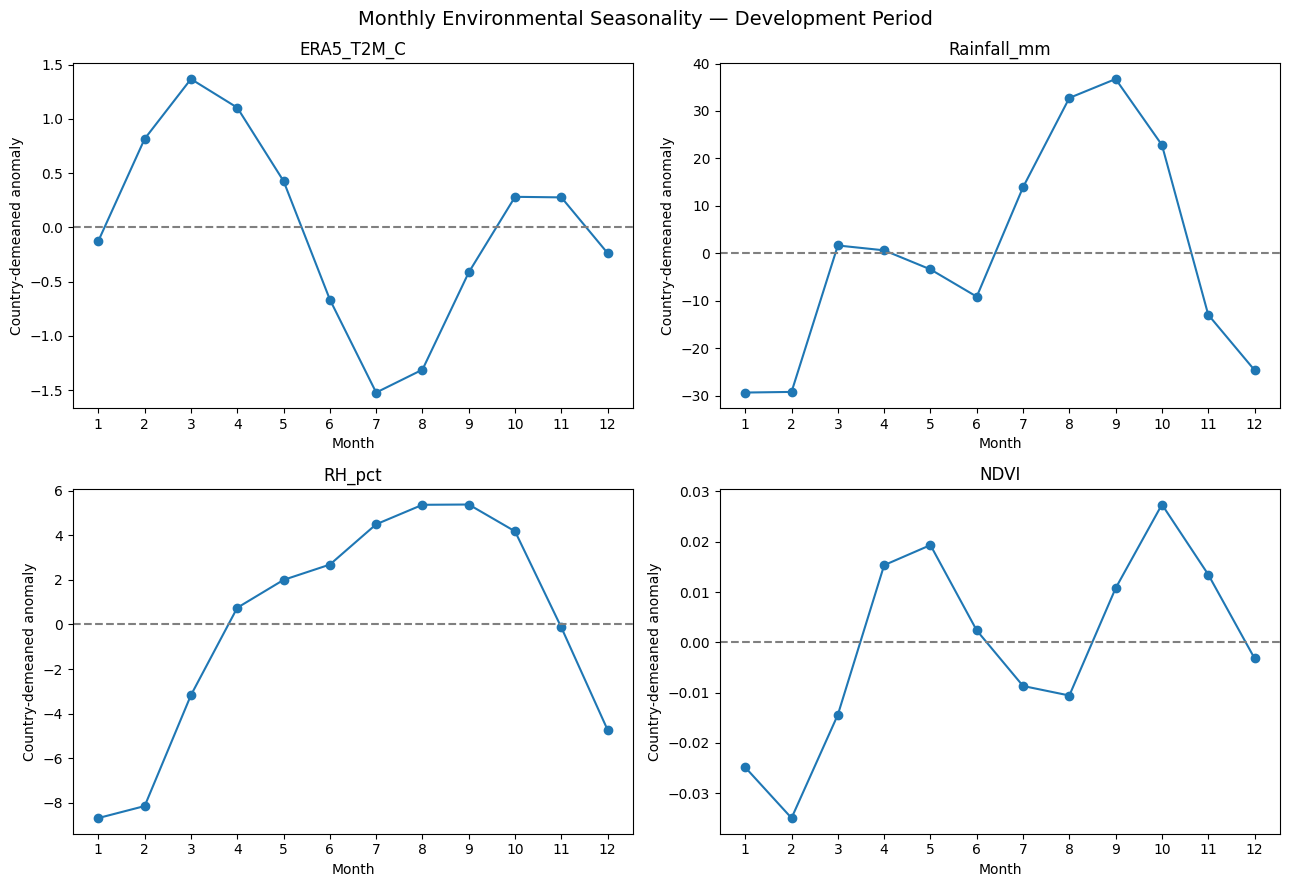


CELL 10 COMPLETED SUCCESSFULLY


In [10]:

# ============================================================
# BIML 2.0 — CELL 10
# ENVIRONMENTAL TEMPORAL DYNAMICS AND VARIABILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Development period only
dev_env = env.loc[env["Year"] <= 2020].copy()

variables = [
    "ERA5_T2M_C",
    "Rainfall_mm",
    "RH_pct",
    "NDVI",
    "NDWI",
    "MODIS_Night_LST_C",
    "Landsat_LST_C"
]

results = []

for variable in variables:

    df = dev_env[
        ["Country", "Year", "Month", variable]
    ].dropna().copy()

    # Between-country variation
    country_means = df.groupby("Country")[variable].mean()
    between_sd = country_means.std()

    # Within-country variation
    df["anomaly"] = (
        df[variable]
        - df.groupby("Country")[variable].transform("mean")
    )
    within_sd = df["anomaly"].std()

    # Monthly temporal persistence within each country
    df = df.sort_values(["Country", "Year", "Month"])

    df["lag1"] = df.groupby("Country")[variable].shift(1)

    # Ensure the preceding observation is exactly one month earlier
    df["period"] = pd.PeriodIndex(
        year=df["Year"],
        month=df["Month"].astype(int),
        freq="M"
    )

    df["previous_period"] = (
        df.groupby("Country")["period"].shift(1)
    )

    valid = (
        df["previous_period"].notna()
        & (
            df["period"].astype(int)
            - df["previous_period"].astype(int) == 1
        )
    )

    temporal_corr = df.loc[
        valid, [variable, "lag1"]
    ].corr().iloc[0, 1]

    # Linear trend of country-mean annual values
    annual = (
        df.groupby(["Country", "Year"])[variable]
        .mean()
        .reset_index()
    )

    slopes = []

    for country, group in annual.groupby("Country"):
        group = group.dropna(subset=[variable])

        if len(group) >= 5:
            slope = np.polyfit(
                group["Year"],
                group[variable],
                1
            )[0]
            slopes.append(slope)

    results.append({
        "variable": variable,
        "n_months": len(df),
        "between_country_sd": between_sd,
        "within_country_sd": within_sd,
        "between_within_ratio": (
            between_sd / within_sd
            if within_sd > 0 else np.nan
        ),
        "monthly_lag1_correlation": temporal_corr,
        "median_annual_trend": np.median(slopes)
    })

temporal_diagnostics = pd.DataFrame(results)

print("=" * 80)
print("BIML 2.0 — ENVIRONMENTAL TEMPORAL DIAGNOSTICS")
print("Development period: 2013–2020")
print("=" * 80)

print(
    temporal_diagnostics.round(4).to_string(index=False)
)

temporal_diagnostics.to_csv(
    TABLE_DIR / "environmental_temporal_diagnostics.csv",
    index=False
)

# ------------------------------------------------------------
# Visualize country-demeaned monthly seasonality
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_vars = [
    "ERA5_T2M_C",
    "Rainfall_mm",
    "RH_pct",
    "NDVI"
]

for ax, variable in zip(axes.flat, plot_vars):

    tmp = dev_env[
        ["Country", "Month", variable]
    ].dropna().copy()

    tmp["anomaly"] = (
        tmp[variable]
        - tmp.groupby("Country")[variable].transform("mean")
    )

    monthly = (
        tmp.groupby("Month")["anomaly"]
        .agg(["mean", "std"])
    )

    ax.plot(
        monthly.index,
        monthly["mean"],
        marker="o"
    )

    ax.axhline(0, linestyle="--", color="gray")

    ax.set_title(variable)
    ax.set_xlabel("Month")
    ax.set_ylabel("Country-demeaned anomaly")
    ax.set_xticks(range(1, 13))

plt.suptitle(
    "Monthly Environmental Seasonality — Development Period",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "environmental_seasonality.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nCELL 10 COMPLETED SUCCESSFULLY")


COUNTRY-SPECIFIC SEASONALITY DIAGNOSTICS
Development period: 2013–2020
         variable  original_sd  deseasonalized_sd  remaining_sd_ratio  missing_anomalies
       ERA5_T2M_C       3.2064             0.5532              0.1725                  0
      Rainfall_mm      99.0899            26.4409              0.2668                  0
           RH_pct      20.0895             3.4606              0.1723                  0
             NDVI       0.1716             0.0462              0.2695                 81
             NDWI       0.1126             0.0594              0.5273                 80
MODIS_Night_LST_C       2.7209             0.6247              0.2296                  0
    Landsat_LST_C       6.3403             1.9609              0.3093                 85


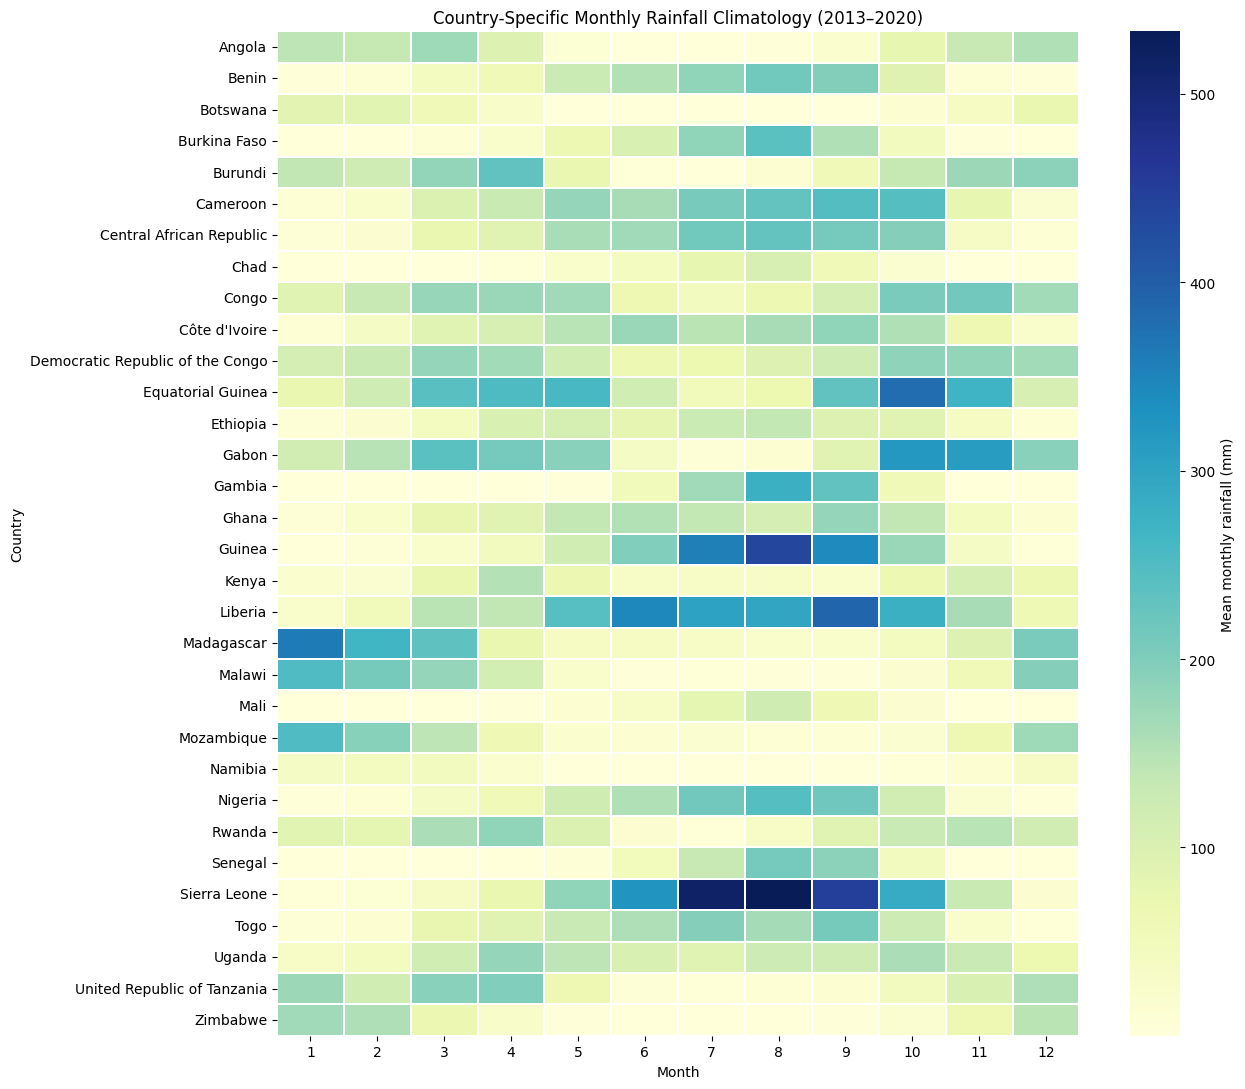


CELL 11 COMPLETED SUCCESSFULLY


In [11]:

# ============================================================
# BIML 2.0 — CELL 11
# COUNTRY-SPECIFIC SEASONALITY AND CLIMATE ANOMALIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "ERA5_T2M_C",
    "Rainfall_mm",
    "RH_pct",
    "NDVI",
    "NDWI",
    "MODIS_Night_LST_C",
    "Landsat_LST_C"
]

# Development period only
climate_dev = env.loc[
    env["Year"].between(2013, 2020)
].copy()

climate_dev = climate_dev.sort_values(
    ["Country", "Year", "Month"]
).reset_index(drop=True)

# ------------------------------------------------------------
# A. Country-month climatology
# ------------------------------------------------------------

climatology = (
    climate_dev
    .groupby(["Country", "Month"])[variables]
    .agg(["mean", "std", "count"])
)

climatology.columns = [
    f"{variable}_{stat}"
    for variable, stat in climatology.columns
]

climatology = climatology.reset_index()

# ------------------------------------------------------------
# B. Deseasonalized anomalies
# ------------------------------------------------------------

anomaly_data = climate_dev.copy()

for variable in variables:

    monthly_mean = (
        anomaly_data
        .groupby(["Country", "Month"])[variable]
        .transform("mean")
    )

    monthly_std = (
        anomaly_data
        .groupby(["Country", "Month"])[variable]
        .transform("std")
    )

    anomaly_data[f"{variable}_anomaly"] = (
        anomaly_data[variable] - monthly_mean
    )

    anomaly_data[f"{variable}_zscore"] = (
        anomaly_data[f"{variable}_anomaly"]
        / monthly_std.replace(0, np.nan)
    )

# ------------------------------------------------------------
# C. Quantify how much variation remains
# ------------------------------------------------------------

results = []

for variable in variables:

    original_sd = anomaly_data[variable].std()

    anomaly_sd = anomaly_data[
        f"{variable}_anomaly"
    ].std()

    results.append({
        "variable": variable,
        "original_sd": original_sd,
        "deseasonalized_sd": anomaly_sd,
        "remaining_sd_ratio": (
            anomaly_sd / original_sd
            if original_sd > 0 else np.nan
        ),
        "missing_anomalies": anomaly_data[
            f"{variable}_anomaly"
        ].isna().sum()
    })

seasonality_results = pd.DataFrame(results)

print("=" * 80)
print("COUNTRY-SPECIFIC SEASONALITY DIAGNOSTICS")
print("Development period: 2013–2020")
print("=" * 80)

print(
    seasonality_results.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# D. Examine country-specific rainfall seasonality
# ------------------------------------------------------------

rainfall_climatology = (
    climate_dev
    .groupby(["Country", "Month"])["Rainfall_mm"]
    .mean()
    .unstack("Month")
)

plt.figure(figsize=(13, 11))

sns.heatmap(
    rainfall_climatology,
    cmap="YlGnBu",
    linewidths=0.2,
    cbar_kws={"label": "Mean monthly rainfall (mm)"}
)

plt.title(
    "Country-Specific Monthly Rainfall Climatology (2013–2020)"
)
plt.xlabel("Month")
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "country_rainfall_climatology.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# E. Save reproducible outputs
# ------------------------------------------------------------

climatology.to_csv(
    TABLE_DIR / "country_month_climatology.csv",
    index=False
)

seasonality_results.to_csv(
    TABLE_DIR / "seasonality_variance_diagnostics.csv",
    index=False
)

anomaly_data.to_csv(
    DATA_DIR / "BIML_environmental_anomalies_development.csv",
    index=False
)

print("\nCELL 11 COMPLETED SUCCESSFULLY")


In [12]:

# ============================================================
# BIML 2.0 — CELL 12
# LAGGED ENVIRONMENTAL ANOMALIES AND INCIDENCE CHANGES
# ============================================================

import numpy as np
import pandas as pd

variables = [
    "ERA5_T2M_C",
    "Rainfall_mm",
    "RH_pct",
    "NDVI",
    "NDWI",
    "MODIS_Night_LST_C",
    "Landsat_LST_C"
]

# ------------------------------------------------------------
# A. Annual summaries of deseasonalized anomalies
# ------------------------------------------------------------

anomaly_columns = [
    f"{variable}_anomaly"
    for variable in variables
]

annual_anomalies = (
    anomaly_data
    .groupby(["Country", "Year"])[anomaly_columns]
    .agg(["mean", "std"])
)

annual_anomalies.columns = [
    f"{variable}_{stat}"
    for variable, stat in annual_anomalies.columns
]

annual_anomalies = annual_anomalies.reset_index()

# ------------------------------------------------------------
# B. Construct previous-year environmental anomalies
# ------------------------------------------------------------

annual_anomalies = annual_anomalies.sort_values(
    ["Country", "Year"]
).reset_index(drop=True)

feature_columns = [
    c for c in annual_anomalies.columns
    if c not in ["Country", "Year"]
]

previous_year = annual_anomalies[
    ["Country", "Year"] + feature_columns
].copy()

# Explicit year shift avoids accidentally linking
# nonconsecutive observations.
previous_year["Year"] += 1

previous_year = previous_year.rename(
    columns={
        feature: f"{feature}_lag1"
        for feature in feature_columns
    }
)

# ------------------------------------------------------------
# C. Join with development-period incidence
# ------------------------------------------------------------

incidence_dev = panel.loc[
    panel["Year"].between(2014, 2020),
    ["Country", "Year", "Incidence_change"]
].copy()

lagged_panel = incidence_dev.merge(
    previous_year,
    on=["Country", "Year"],
    how="left",
    validate="one_to_one"
)

assert len(lagged_panel) == 32 * 7

lagged_features = [
    f"{feature}_lag1"
    for feature in feature_columns
]

# ------------------------------------------------------------
# D. Calculate exploratory correlations
# ------------------------------------------------------------

results = []

for feature in lagged_features:

    pair = lagged_panel[
        [feature, "Incidence_change"]
    ].dropna()

    if len(pair) < 30:
        continue

    results.append({
        "feature": feature,
        "n": len(pair),
        "pearson": pair[feature].corr(
            pair["Incidence_change"],
            method="pearson"
        ),
        "spearman": pair[feature].corr(
            pair["Incidence_change"],
            method="spearman"
        )
    })

lagged_correlations = pd.DataFrame(results)

lagged_correlations["abs_spearman"] = (
    lagged_correlations["spearman"].abs()
)

lagged_correlations = lagged_correlations.sort_values(
    "abs_spearman",
    ascending=False
)

print("=" * 80)
print("PREVIOUS-YEAR ENVIRONMENTAL ANOMALIES")
print("VERSUS CURRENT-YEAR INCIDENCE CHANGES")
print("Development targets: 2014–2020")
print("=" * 80)

print(
    lagged_correlations.round(4).to_string(index=False)
)

print("\nObservations:", len(lagged_panel))
print("Countries:", lagged_panel["Country"].nunique())

lagged_correlations.to_csv(
    TABLE_DIR / "lagged_environmental_correlations.csv",
    index=False
)

lagged_panel.to_csv(
    DATA_DIR / "BIML_lagged_anomaly_audit.csv",
    index=False
)

print("\nCELL 12 COMPLETED SUCCESSFULLY")


PREVIOUS-YEAR ENVIRONMENTAL ANOMALIES
VERSUS CURRENT-YEAR INCIDENCE CHANGES
Development targets: 2014–2020
                            feature   n  pearson  spearman  abs_spearman
    Landsat_LST_C_anomaly_mean_lag1 224  -0.0473   -0.0693        0.0693
        ERA5_T2M_C_anomaly_std_lag1 224   0.0432    0.0684        0.0684
           RH_pct_anomaly_mean_lag1 224  -0.0009   -0.0492        0.0492
      Rainfall_mm_anomaly_mean_lag1 224   0.0028   -0.0367        0.0367
            RH_pct_anomaly_std_lag1 224  -0.0546    0.0352        0.0352
       ERA5_T2M_C_anomaly_mean_lag1 224   0.0438    0.0331        0.0331
 MODIS_Night_LST_C_anomaly_std_lag1 224   0.0051   -0.0253        0.0253
       Rainfall_mm_anomaly_std_lag1 224  -0.0189   -0.0238        0.0238
              NDWI_anomaly_std_lag1 224  -0.0198   -0.0192        0.0192
     Landsat_LST_C_anomaly_std_lag1 224  -0.0216   -0.0147        0.0147
              NDVI_anomaly_std_lag1 224  -0.0232   -0.0115        0.0115
MODIS_Night_LST_C

In [13]:

# ============================================================
# BIML 2.0 — CELL 13
# BIOLOGICAL INPUT READINESS AUDIT
# ============================================================

import numpy as np
import pandas as pd

bio_inputs = {
    "ERA5_T2M_C": {
        "role": "Ambient air temperature",
        "expected_unit": "degrees Celsius",
        "required": True
    },
    "Rainfall_mm": {
        "role": "Rainfall / potential habitat conditions",
        "expected_unit": "mm per month",
        "required": False
    },
    "RH_pct": {
        "role": "Relative humidity / mosquito survival conditions",
        "expected_unit": "percent",
        "required": False
    },
    "NDVI": {
        "role": "Vegetation and habitat context",
        "expected_unit": "dimensionless",
        "required": False
    },
    "NDWI": {
        "role": "Surface moisture context",
        "expected_unit": "dimensionless",
        "required": False
    },
    "MODIS_Night_LST_C": {
        "role": "Nighttime land surface temperature",
        "expected_unit": "degrees Celsius",
        "required": False
    },
    "Landsat_LST_C": {
        "role": "Land surface temperature",
        "expected_unit": "degrees Celsius",
        "required": False
    }
}

rows = []

for variable, info in bio_inputs.items():

    values = pd.to_numeric(
        env[variable], errors="coerce"
    )

    rows.append({
        "variable": variable,
        "role": info["role"],
        "expected_unit": info["expected_unit"],
        "required": info["required"],
        "observations": len(values),
        "missing": values.isna().sum(),
        "missing_pct": 100 * values.isna().mean(),
        "min": values.min(),
        "median": values.median(),
        "max": values.max(),
        "nonfinite": np.isinf(values).sum()
    })

bio_audit = pd.DataFrame(rows)

print("=" * 85)
print("BIOLOGICAL INPUT READINESS")
print("=" * 85)

print(bio_audit.round(4).to_string(index=False))

# ------------------------------------------------------------
# Temperature-domain investigation
# These are diagnostic bins, NOT biological validity limits.
# ------------------------------------------------------------

temperature = env["ERA5_T2M_C"]

bins = [-np.inf, 15, 18, 22, 26, 30, 34, np.inf]

labels = [
    "<15",
    "15–18",
    "18–22",
    "22–26",
    "26–30",
    "30–34",
    ">34"
]

temperature_groups = pd.cut(
    temperature,
    bins=bins,
    labels=labels,
    right=False
)

temperature_distribution = (
    temperature_groups.value_counts()
    .reindex(labels, fill_value=0)
)

print("\n" + "=" * 85)
print("TEMPERATURE DISTRIBUTION")
print("Diagnostic intervals only")
print("=" * 85)

print(temperature_distribution.to_string())

print("\nCountry-level temperature ranges:")

country_temperature = (
    env.groupby("Country")["ERA5_T2M_C"]
    .agg(["min", "median", "max"])
    .sort_values("median")
)

print(country_temperature.round(3).to_string())

bio_audit.to_csv(
    TABLE_DIR / "biological_input_readiness.csv",
    index=False
)

country_temperature.to_csv(
    TABLE_DIR / "country_temperature_ranges.csv"
)

print("\nCELL 13 COMPLETED SUCCESSFULLY")


BIOLOGICAL INPUT READINESS
         variable                                             role   expected_unit  required  observations  missing  missing_pct     min  median      max  nonfinite
       ERA5_T2M_C                          Ambient air temperature degrees Celsius      True          4608        0       0.0000 13.7803 24.8266  35.4891          0
      Rainfall_mm          Rainfall / potential habitat conditions    mm per month     False          4608        0       0.0000  0.0000 73.8045 634.4154          0
           RH_pct Relative humidity / mosquito survival conditions         percent     False          4608        0       0.0000 10.8522 67.7540  92.4858          0
             NDVI                   Vegetation and habitat context   dimensionless     False          4608       85       1.8446 -0.8167  0.5126   0.8410          0
             NDWI                         Surface moisture context   dimensionless     False          4608       84       1.8229 -0.7520 -0.5137   0